In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

Load Dataset

In [4]:
df = pd.read_csv("titanic_dataset.csv")

In [5]:
df.shape

(891, 15)

In [6]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [8]:
# Identify numerical and categorical features
num_cols = ["age", "fare", "sibsp", "parch"]
cat_cols = ["survived", "pclass", "pclass", "sex", "embarked", "class", "who", "adult_male", "deck", "embark_town", "alone"]

print("\nNumerical columns:", num_cols)
print("\nCategorical columns:", cat_cols)


Numerical columns: ['age', 'fare', 'sibsp', 'parch']

Categorical columns: ['survived', 'pclass', 'pclass', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']


Numerical Features Analysis

In [9]:
df[num_cols].head()

,age,fare,sibsp,parch
0,22.0,7.2500,1,0
1,38.0,71.2833,1,0
2,26.0,7.9250,0,0
3,35.0,53.1000,1,0
4,35.0,8.0500,0,0


Summary Statistics

In [11]:
print("Summary Statistics")
df[num_cols].describe()

Summary Statistics


,age,fare,sibsp,parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


Mean, Median, Mode

In [16]:
print("Mean:")
print(df[num_cols].mean())

print("-"*50)

print("Median:")
print(df[num_cols].median())

print("-"*50)

print("Mode:")
print(df[num_cols].mode().iloc[0])

Mean:
age      29.699118
fare     32.204208
sibsp     0.523008
parch     0.381594
dtype: float64
--------------------------------------------------
Median:
age      28.0000
fare     14.4542
sibsp     0.0000
parch     0.0000
dtype: float64
--------------------------------------------------
Mode:
age      24.00
fare      8.05
sibsp     0.00
parch     0.00
Name: 0, dtype: float64


Variance and Standard Deviation

In [17]:
print("Variance:")
print(df[num_cols].var())

print("-"*50)


print("Standard Deviation:")
print(df[num_cols].std())

Variance:
age       211.019125
fare     2469.436846
sibsp       1.216043
parch       0.649728
dtype: float64
--------------------------------------------------
Standard Deviation:
age      14.526497
fare     49.693429
sibsp     1.102743
parch     0.806057
dtype: float64


Skewness Value

In [18]:
print("\nSkewness:")
print(df[num_cols].skew())


print("\nKurtosis:")
print(df[num_cols].kurtosis())


Skewness:
age      0.389108
fare     4.787317
sibsp    3.695352
parch    2.749117
dtype: float64

Kurtosis:
age       0.178274
fare     33.398141
sibsp    17.880420
parch     9.778125
dtype: float64


Histograms

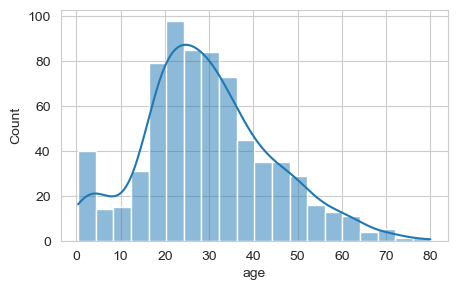

In [24]:
plt.figure(figsize=(5,3))
sns.histplot(df["age"], kde=True)
plt.show()

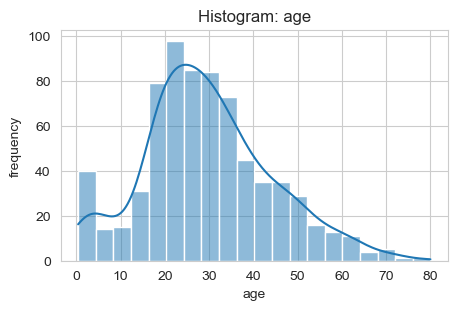

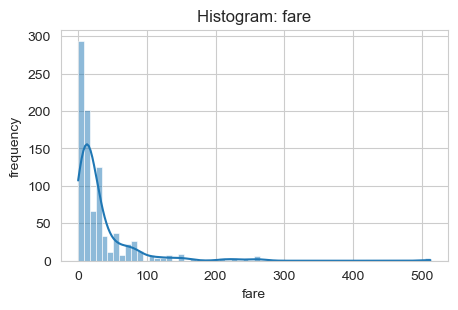

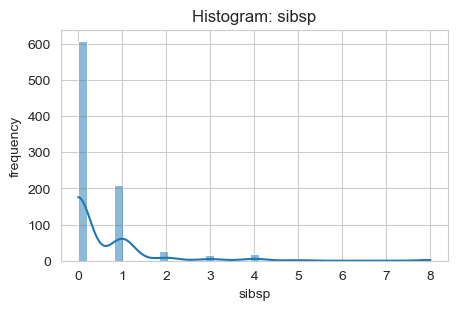

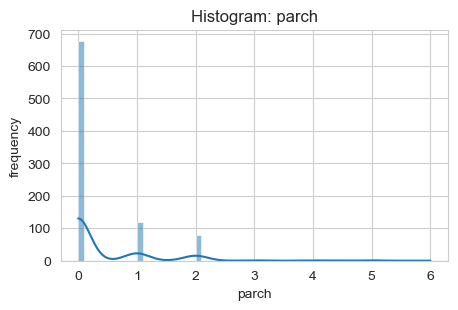

In [29]:
for col in num_cols:
    plt.figure(figsize=(5,3))
    sns.histplot(df[col], kde=True)
    plt.title(f"Histogram: {col}")
    plt.xlabel(col)
    plt.ylabel("frequency")
    plt.show()

Boxplot

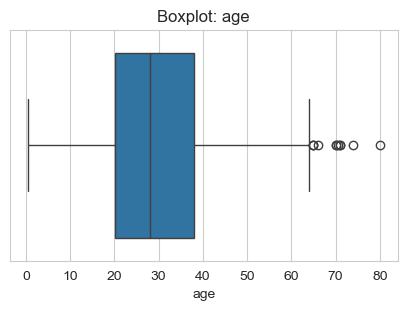

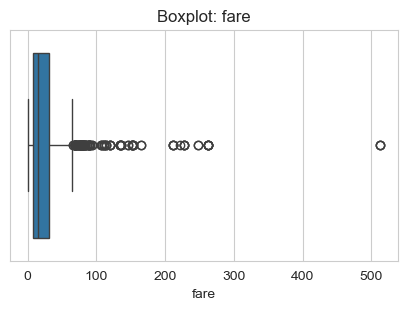

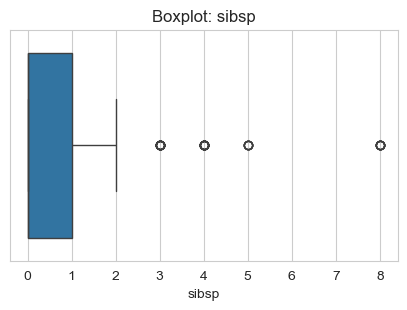

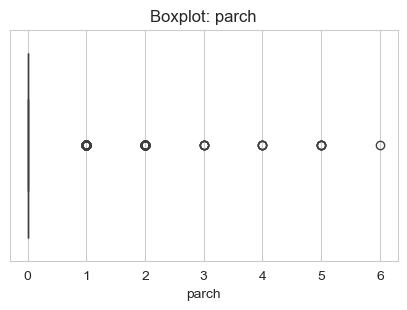

In [30]:
for col in num_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

Categorical Features - Analysis

In [31]:
df[cat_cols].head()

,survived,pclass,pclass,sex,embarked,class,who,adult_male,deck,embark_town,alone
0,0,3,3,male,S,Third,man,True,NaN,Southampton,False
1,1,1,1,female,C,First,woman,False,C,Cherbourg,False
2,1,3,3,female,S,Third,woman,False,NaN,Southampton,True
3,1,1,1,female,S,First,woman,False,C,Southampton,False
4,0,3,3,male,S,Third,man,True,NaN,Southampton,True


Frequency Table

In [33]:
print(df["pclass"].value_counts())
print("-"*50)
df["pclass"].value_counts(normalize=True)

pclass
3    491
1    216
2    184
Name: count, dtype: int64
--------------------------------------------------


pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64

In [37]:
for col in cat_cols:
    print(f"Frequency table for {col}")
    print(df[col].value_counts())
    print(f"Proportion for {col}")
    print(df[col].value_counts(normalize=True))
    print("-"*50)

Frequency table for survived
survived
0    549
1    342
Name: count, dtype: int64
Proportion for survived
survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64
--------------------------------------------------
Frequency table for pclass
pclass
3    491
1    216
2    184
Name: count, dtype: int64
Proportion for pclass
pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64
--------------------------------------------------
Frequency table for pclass
pclass
3    491
1    216
2    184
Name: count, dtype: int64
Proportion for pclass
pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64
--------------------------------------------------
Frequency table for sex
sex
male      577
female    314
Name: count, dtype: int64
Proportion for sex
sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64
--------------------------------------------------
Frequency table for embarked
embarked
S    644
C    168
Q     

Count Plot

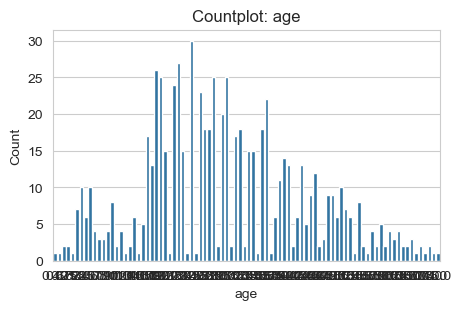

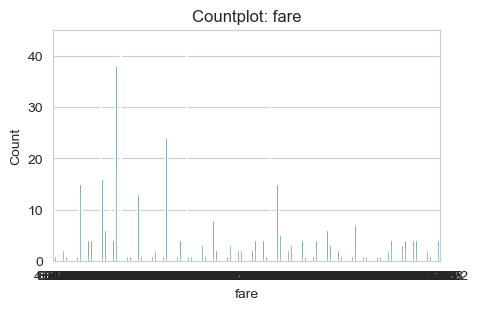

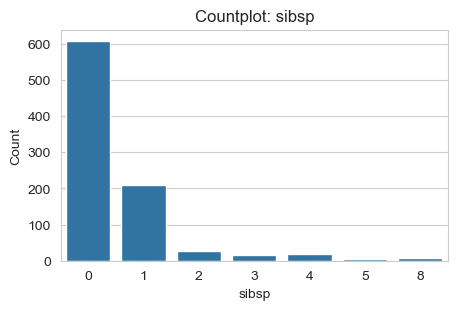

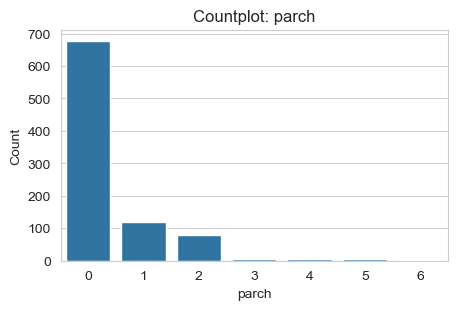

In [40]:
for col in num_cols:
    plt.figure(figsize=(5,3))
    sns.countplot(x=df[col])
    plt.title(f"Countplot: {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()